# Experiment 7: Logistic Regression
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Write a program to implement the **Logistic Regression** algorithm in Python.

## Theory
Logistic regression models the probability of the positive class with the sigmoid function:

`P(y=1 | x) = 1 / (1 + exp(-(w.x + b)))`

The weights are learned by minimising the log-loss (cross-entropy) with gradient descent. The *Breast Cancer Wisconsin* data set (malignant vs benign) is used.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             roc_curve, roc_auc_score)

data = load_breast_cancer()
X, y = data.data, data.target
print('Samples:', X.shape[0], '| Features:', X.shape[1], '| Classes:', data.target_names.tolist())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler().fit(X_train)
Xtr, Xte = scaler.transform(X_train), scaler.transform(X_test)

Samples: 569 | Features: 30 | Classes: ['malignant', 'benign']


From-scratch test accuracy: 0.9737


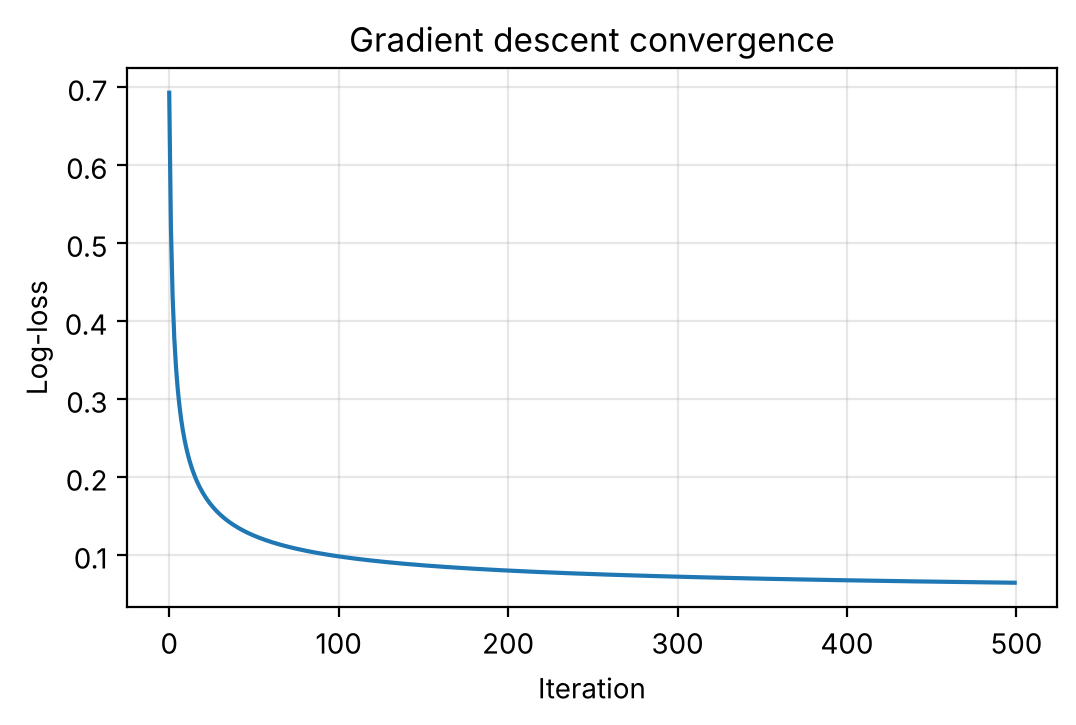

In [2]:
# --- From-scratch logistic regression (batch gradient descent) ---
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

w = np.zeros(Xtr.shape[1]); b = 0.0
lr, epochs = 0.1, 500
losses = []
for _ in range(epochs):
    p = sigmoid(Xtr @ w + b)
    loss = -np.mean(y_train * np.log(p + 1e-12) + (1 - y_train) * np.log(1 - p + 1e-12))
    losses.append(loss)
    w -= lr * (Xtr.T @ (p - y_train)) / len(y_train)
    b -= lr * np.mean(p - y_train)

pred_scratch = (sigmoid(Xte @ w + b) >= 0.5).astype(int)
print('From-scratch test accuracy:', round(accuracy_score(y_test, pred_scratch), 4))

plt.figure(figsize=(6, 3.5))
plt.plot(losses); plt.xlabel('Iteration'); plt.ylabel('Log-loss')
plt.title('Gradient descent convergence'); plt.grid(alpha=0.3); plt.show()

scikit-learn test accuracy: 0.9825
ROC-AUC: 0.9954 

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



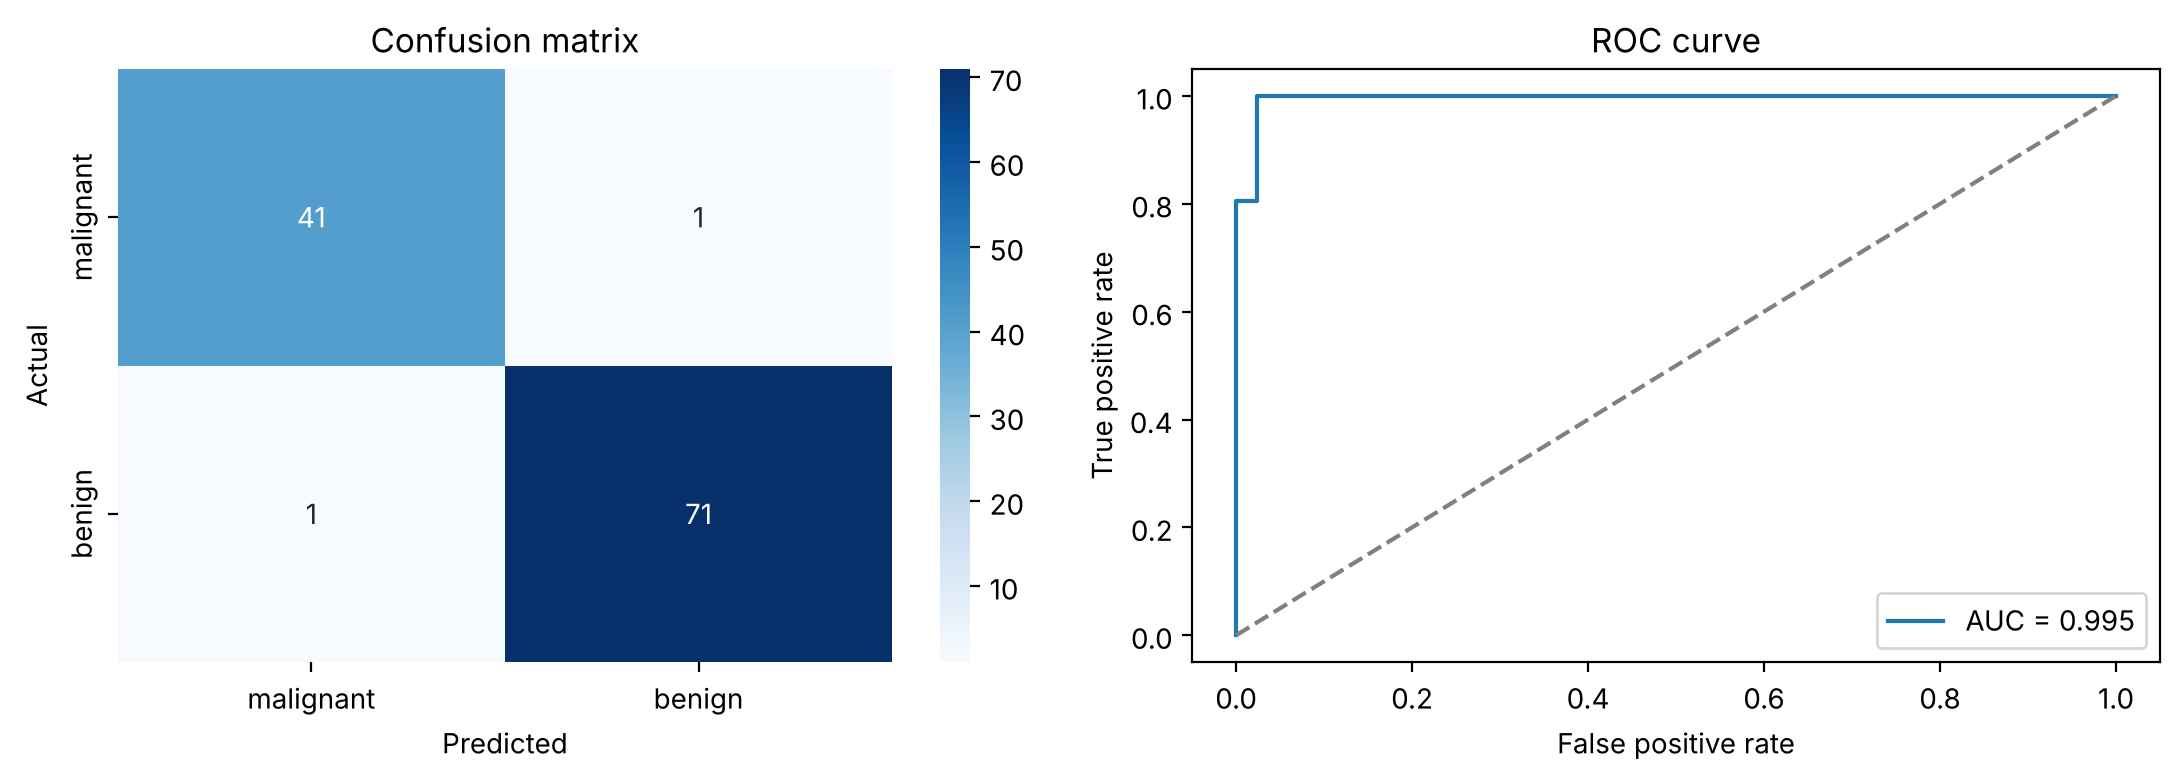

In [3]:
# --- scikit-learn Logistic Regression ---
model = LogisticRegression(max_iter=1000).fit(Xtr, y_train)
y_pred = model.predict(Xte)
y_prob = model.predict_proba(Xte)[:, 1]

print('scikit-learn test accuracy:', round(accuracy_score(y_test, y_pred), 4))
print('ROC-AUC:', round(roc_auc_score(y_test, y_prob), 4), '\n')
print(classification_report(y_test, y_pred, target_names=data.target_names))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', ax=ax[0],
            xticklabels=data.target_names, yticklabels=data.target_names)
ax[0].set_xlabel('Predicted'); ax[0].set_ylabel('Actual'); ax[0].set_title('Confusion matrix')
fpr, tpr, _ = roc_curve(y_test, y_prob)
ax[1].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, y_prob):.3f}')
ax[1].plot([0, 1], [0, 1], '--', color='gray')
ax[1].set_xlabel('False positive rate'); ax[1].set_ylabel('True positive rate')
ax[1].set_title('ROC curve'); ax[1].legend(); plt.tight_layout(); plt.show()

## Result
Logistic regression separates malignant and benign tumours with about 97-98 % accuracy and an ROC-AUC close to 1. The scratch gradient-descent version is close to scikit-learn's accuracy (a little lower after only 500 iterations).